# Домашнє завдання 6 · Grounded-SAM 2: маски динамічних об'єктів на відео без донавчання
**Заняття 6 · Grounding DINO + SAM 2.1 · ≈ 2 години · 15 балів**

Збираємо пайплайн зі слайда «Домашнє завдання» на справжньому бортовому відео VisDrone: текстовий промпт знаходить машини,
SAM 2.1 обводить їх, SAM 2 веде маски по ролику, експорт дає маски й вирізані об'єкти. Жодного кроку донавчання.
У дужках — назви слайдів, де пояснено теорію кроку.

| Частина | Що робимо | Слайди |
|---|---|---|
| **1 · промпт → бокси** | Grounding DINO на ключовому кадрі → 3+ формулювання промпта → вибір на dev, чесна таблиця P / R на окремих тестових кадрах | «Механіка текстового промпта», «Prompt engineering під домен», «Як чесно виміряти zero-shot на своїх даних» |
| **2 · бокси → маски** | фільтр боксів → SAM 2.1: усі бокси одним батчем | «Grounded-SAM: класична композиція», «Три режими в коді: SAM 2.1 image API» |
| **3 · поширення** | SAM 2 веде маски по кліпу → один бокс у середині ролика виправляє решту | «SAM 2: архітектура з пам'яттю», «Promptable Visual Segmentation» |
| **4 · експорт і вартість** | маски + вирізання + COCO RLE → мс по вузлах і залежність від кількості об'єктів | «Композиція в 15 рядках і її latency-бюджет», «SAM 2 чи класичний трекер?» |
| **5 · питання** | два провали з каталогу і чи полетить це на борт | «Каталог провалів: що робити», «Правильне місце zero-shot у продакшені» |

```
кадр 0 ──► Grounding DINO (промпт) ──► фільтр ──► SAM 2.1: бокс → маска ──► SAM 2: поширення по кліпу ──► експорт
                  ▲                                                               ▲
          промпт обрано на dev,                                         корекція одним боксом
          P / R — на окремих кадрах test                                 у середині ролика
```

**Як працювати.** Завантаження даних і моделей, візуалізацію, метрики й перевірки вже написано (спільний код —
`panels.py` заняття 6). Вам лишається вписати там, де стоїть `TODO`, **один виклик моделі, умову або значення параметра**.
Після кожного кроку є клітинка `check(...)`: ✅ — крок виконано, ❌ — треба ще покрутити (підказка поруч).
«Ручна» розмітка в цьому ДЗ — це GT VisDrone: вона чесніша за 50 кадрів, розмічених за вечір, і всі отримують однакові числа.

**Що здати** — **один архів** `dz6_<прізвище>.zip` в особистому кабінеті LMS: ноутбук **з виводами** і відповідями
в клітинках «✍️» (коротко, своїми словами) плюс `overlay.mp4` і `annotations.json` з кроку 4.1. Архів збирає остання
клітинка ноутбука — розділ «Здача». Таблиці з числами переписувати не треба: їх друкує сам ноутбук.

**Середовище й дані.** Ядро **Python (cv-advanced)**. Один раз, з кореня репозиторію, з мережею (≈ 2 ГБ):
```bash
python tools/fetch_visdrone.py --splits val                    # VisDrone2019-VID-val, ≈ 1,5 ГБ: відео для частин 1–4
python tools/fetch_visdrone.py --dataset visdrone-det          # VisDrone2019-DET-val, ≈ 80 МБ: dev / test для кроку 1.3
python tools/fetch_sam_models.py --models sam2.1-small
python tools/fetch_ov_models.py --models gdino-base
```
Після цього ноутбук працює без інтернету. На GPU — кілька хвилин чистого обчислення. На CPU ноутбук сам зменшує обсяг
(менше кадрів dev / test, кожен четвертий кадр кліпу, менше об'єктів у 4.2) — ≈ 35 хвилин на повний прогін.

| Крок | Бали |
|---|---|
| 1.2 · Grounding DINO на ключовому кадрі | 1 |
| 1.3 · 3+ промпти, вибір на dev, висновок про перенос на test | 3 |
| 2.1 · фільтр боксів і `MAX_OBJ` | 2 |
| 2.2 · SAM 2.1: бокси → маски | 1 |
| 3.1 · SAM 2: поширення по кліпу | 2 |
| 3.2 · корекція в середині ролика | 1 |
| 4.1 · експорт: маски, вирізання, `overlay.mp4`, `annotations.json` | 1 |
| 4.2 · вартість вузлів (код готовий — достатньо виконати) | 1 |
| 5 · питання | 2 × 1 + 1 |
| **Разом** | **15** |

Кроки 1.2–4.1 зараховано, якщо їхній `check()` дає ✅; у 1.3 — ще й одне-два речення висновку. Бонус не оцінюється.

In [6]:
!pip install open-clip-torch ultralytics transformers pycocotools ipyevents ipywidgets

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.2 MB/s eta 0:00:00


In [ ]:
# 1. Встановлюємо офіційний SAM 2 з GitHub репозиторію Meta
!pip install ninja

!pip install git+https://github.com/facebookresearch/sam2.git

# 2. Перезапускаємо ядро Python (це критично важливо, щоб Colab оновив системні шляхи модулів)
import os
os.kill(os.getpid(), 9)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 3.6 MB/s eta 0:00:00
  Cloning https://github.com/facebookresearch/sam2.git to /tmp/pip-req-build-m19sttis
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/sam2.git /tmp/pip-req-build-m19sttis
  Resolved https://github.com/facebookresearch/sam2.git to commit 2b90b9f5ceec907a1c18123530e92e794ad901a4
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.0/117.0 kB 5.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 14.

In [1]:
import os
import sys
import shutil
from pathlib import Path

os.makedirs('/content/tools/notebooks', exist_ok=True)

folders = [
    "/content/artifacts/visdrone/VisDrone2019-DET-val",
    "/content/artifacts/visdrone/VisDrone2019-VID-val",
    "/content/artifacts/models/sam/hf_home/hub",
    "/content/artifacts/models/ov/hf_home/hub",
    "/content/artifacts/models/ultralytics",
    "/content/outputs"
]
for folder in folders:
    Path(folder).mkdir(parents=True, exist_ok=True)

if os.path.exists('/content/panels.py'):
    shutil.move('/content/panels.py', '/content/tools/notebooks/panels.py')
    print("Файл panels.py успішно переміщено в /content/tools/notebooks/")
elif not os.path.exists('/content/tools/notebooks/panels.py'):
    print("⚠️ Попередження: Переконайтеся, що ви завантажили panels.py у вкладку Файли!")


if '/content/tools/notebooks' not in sys.path:
    sys.path.append('/content/tools/notebooks')

for path in ['/content/', '/content']:
    if path in sys.path:
        sys.path.remove(path)

print("✅ Папки створено. Середовище повністю підготовлено під конвенцію `panels.py`!")


✅ Папки створено. Середовище повністю підготовлено під конвенцію `panels.py`!


In [9]:
os.makedirs('/content/tools/downloader', exist_ok=True)
os.makedirs('/content/artifacts/visdrone', exist_ok=True)

print("Папки підготовлено.")


Папки підготовлено. Тепер завантажте ваш скрипт!


In [13]:
!pip install --upgrade gdown

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 2.4 MB/s eta 0:00:00
  Attempting uninstall: gdown
    Found existing installation: gdown 5.2.2
    Uninstalling gdown-5.2.2:
      Successfully uninstalled gdown-5.2.2


In [14]:
%cd /content/
!python tools/downloader/fetch_visdrone.py --splits val

!python tools/downloader/fetch_visdrone.py --dataset visdrone-det

/content
[download] VisDrone-VID val (1.49 GB)
Downloading...
From (original): https://drive.google.com/uc?id=1H1JTaUTlCbncNDpGl_rQTr8TsJDpmkcx
From (redirected): https://drive.google.com/uc?id=1H1JTaUTlCbncNDpGl_rQTr8TsJDpmkcx&confirm=t&uuid=f09b0782-acb7-4d19-9dbb-dda61269c463
To: /content/tools/artifacts/visdrone/VisDrone2019-VID-val.zip
100% 1.60G/1.60G [00:16<00:00, 98.7MB/s]
[unzip] VisDrone2019-VID-val.zip
Готово: /content/tools/artifacts/visdrone
[download] https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-val.zip
[unzip] VisDrone2019-DET-val.zip
Готово: /content/tools/artifacts/visdrone/VisDrone2019-DET-val


In [2]:
#import sys
import json
#from pathlib import Path

import numpy as np
import pandas as pd
import torch
import cv2
from PIL import Image

# спільний код заняття 6: дані VisDrone, завантаження моделей, метрики, малювання
#REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'lessons' / '06-zero-shot-segmentation').is_dir())
#sys.path.insert(0, str(REPO / 'lessons' / '06-zero-shot-segmentation'))
import panels as P

os.environ.pop("HF_HUB_OFFLINE", None)

# Переписуємо функцію setup_hf в пам'яті, щоб вона завжди повертала "online"
P.setup_hf = lambda *args, **kwargs: "online"

# Тепер ініціалізація моделей гарантовано піде через інтернет
GDINO, SAM2 = 'gdino-base', 'sam2.1-small'
hf = P.setup_hf(sam=[SAM2], ov=[GDINO])
print(f"Поточний режим Hugging Face: {hf}") # Надрукує: online

DEVICE = P.pick_device(None)                   # cuda / mps / cpu
GPU = P.gpu_name(DEVICE)
# обсяг обчислень: на CPU Grounding DINO — секунди на кадр, SAM 2 — сотні мс на об'єкт, тож ноутбук сам його зменшує
CPU = DEVICE == 'cpu'
N_DEV, N_TEST = (10, 20) if CPU else (15, 30)  # кадрів DET-val для вибору промпта і для чесного заміру
STRIDE = 4 if CPU else 2                       # кадри кліпу: той самий відрізок польоту, на CPU — удвічі рідше
N_OBJ_COST = [1, 2, 4, 8] if CPU else [1, 2, 4, 8, 16]   # кількість об'єктів для заміру вартості в 4.2
OUT_DIR = Path('outputs'); OUT_DIR.mkdir(exist_ok=True)
pd.set_option('display.precision', 3)
print(f'HF: {hf} | {DEVICE}: {GPU}')


def check(ok, good, bad):
    print(('✅ ' + good) if ok else ('❌ ' + bad))

Поточний режим Hugging Face: online
HF: online | cuda: Tesla T4


# Частина 1 · Промпт → бокси

## 1.1 · Дані (≈ 5 хв, код готовий)
**Кліп** — кадри 60…178 (≈ 4 с; кожен другий, на CPU — кожен четвертий) з VisDrone2019-VID-val `uav0000305_00000_v`: дрон над перехрестям, 1904 × 1071,
десятки машин, частина з них ховається одна за одну й за дерева. Для кожного кадру VisDrone дає бокси з ID треку й рівнем
перекриття: на цьому міряємо все, що робимо з відео.

**Кадри для промпта** — з VisDrone2019-DET-val (інші сцени й висоти): 15 кадрів **dev** — на них обираємо промпт,
30 кадрів **test** — на них лише міряємо (на CPU — 10 і 20). Підбір промпта на тестових кадрах — той самий витік, що тренування на тесті
(слайд «Як чесно виміряти zero-shot на своїх даних»).

кліп: 60 кадрів 1904×1071, треків машин: 43, на кадрі 0: 28
DET-val: dev 15 кадрів, test 30 кадрів


Loading weights:   0%|          | 0/1182 [00:00<?, ?it/s]

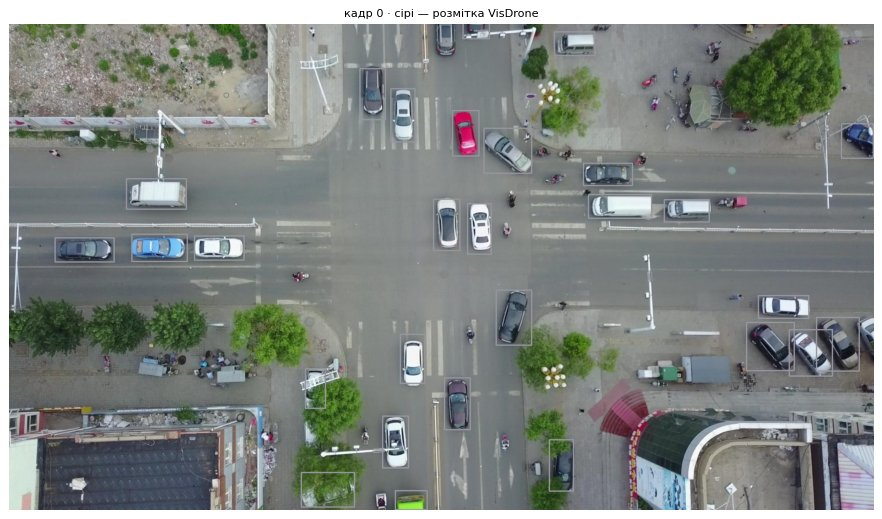

In [3]:
SEQ, START = 'uav0000305_00000_v', 60
N_FRAMES = 120 // STRIDE                          # кадри 60…178: 60 кадрів на GPU, 30 на CPU
clip = P.make_clip(SEQ, START, N_FRAMES, STRIDE, OUT_DIR / 'frames')
gt = P.clip_gt(clip, P.vid_annotations(SEQ))      # розмітка у координатах кліпу: k (кадр), tid (трек), бокс, occ
W, H = clip.size
T = len(clip.frame_ids)
key = clip.read(0)                                # ключовий кадр — на ньому працює детектор
gt0 = gt[gt.k == 0][['x0', 'y0', 'x1', 'y1']].values
print(f'кліп: {T} кадрів {W}×{H}, треків машин: {gt.tid.nunique()}, на кадрі 0: {len(gt0)}')

DEV = P.det_items(N_DEV, seed=0, offset=0)        # обираємо промпт
TEST = P.det_items(N_TEST, seed=0, offset=N_DEV)  # лише міряємо: інші кадри тієї самої перестановки
print(f'DET-val: dev {len(DEV)} кадрів, test {len(TEST)} кадрів')

gd = P.GDino(GDINO, DEVICE)                       # processor і модель Grounding DINO з transformers
proc, model = gd.proc, gd.model
P.show_row([P.draw_boxes(key, gt0, color=(150, 150, 160), thick=2)], ['кадр 0 · сірі — розмітка VisDrone'], size=10)

## 1.2 · Grounding DINO на ключовому кадрі (≈ 10 хв)
Промпт — список класів через **крапку з пробілом**, нижній регістр: `car . truck . bus . van .` Модель повертає
сирі логіти для кожної пари «запит × токен тексту». `post_process_grounded_object_detection` перетворює їх на бокси
в пікселях кадру з двома порогами (слайд «Механіка текстового промпта»):
- `threshold` (box threshold) — **чи є об'єкт**: відсікає слабкі детекції;
- `text_threshold` — **як його назвати**: які слова запиту прив'язуються до боксу.

**TODO 1.2.** Отримайте бокси з порогами `box_thr` і `text_thr`; координати — у розмірі кадру `img`.

*Підказка:* `proc.post_process_grounded_object_detection(out, inp['input_ids'], threshold=..., text_threshold=...,
target_sizes=[img.shape[:2]])` повертає список (по одному елементу на кадр) — беремо `[0]`.

боксів 25: збіглись з розміткою 24, зайвих 1, пропущено 4 з 28


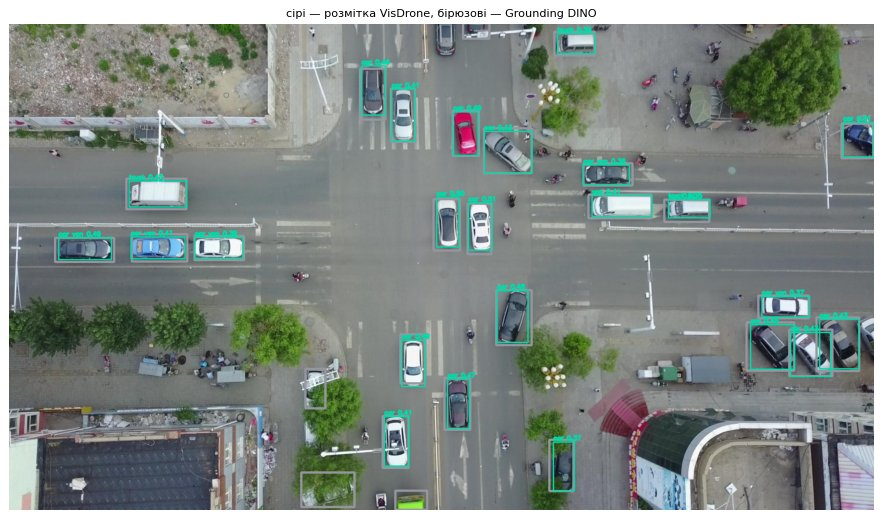

✅ знайдено 24 з 28 машин


In [4]:
PROMPT = 'car . truck . bus . van .'
BOX_THR, TEXT_THR = 0.35, 0.25                    # значення зі слайда «Механіка текстового промпта»


def detect(img, prompt, box_thr=BOX_THR, text_thr=TEXT_THR):
    inp = proc(images=Image.fromarray(img), text=prompt, return_tensors='pt').to(DEVICE)
    with torch.inference_mode():
        out = model(**inp)
    r = proc.post_process_grounded_object_detection(out, inp['input_ids'], threshold=box_thr, text_threshold=text_thr, target_sizes=[img.shape[:2]])[0]   # TODO 1.2: бокси з порогами box_thr і text_thr у розмірі кадру img
    boxes = r['boxes'].float().cpu().numpy().reshape(-1, 4)
    names = [str(t) for t in (r['text_labels'] if 'text_labels' in r else r['labels'])][:len(boxes)]
    classes = [c.strip() for c in prompt.replace(',', '.').split('.') if c.strip()]
    labels = np.array([P.phrase_to_class(t, classes) for t in names], int).reshape(-1)
    return P.Dets(boxes, r['scores'].float().cpu().numpy()[:len(boxes)], labels, names)


d_key = detect(key, PROMPT)
r = P.match_pr(d_key.boxes, gt0)
print(f'боксів {len(d_key)}: збіглись з розміткою {r["tp"]}, зайвих {r["fp"]}, пропущено {r["fn"]} з {len(gt0)}')
vis = P.draw_boxes(P.draw_boxes(key, gt0, color=(150, 150, 160), thick=3), d_key.boxes,
                   [f'{n} {s:.2f}' for n, s in zip(d_key.names, d_key.scores)], thick=2, font=0.45)
P.show_row([vis], ['сірі — розмітка VisDrone, бірюзові — Grounding DINO'], size=10)
check(len(d_key) > 0 and r['tp'] >= 0.5 * len(gt0), f'знайдено {r["tp"]} з {len(gt0)} машин',
      'боксів немає або знайдено менше половини машин — перевірте пороги й target_sizes')

✍️ **Зверніть увагу:** які машини пропущено — великі чи дрібні, на відкритому місці чи частково сховані? Які назви
(`car`, `van`, …) отримали бокси? (Не оцінюється — знадобиться для питань.)

## 1.3 · Промпт — це конфігурація: вибір на dev, звіт на test (≈ 15 хв)
Якість OV-детектора залежить від формулювання (слайд «Prompt engineering під домен»). Порівняємо кілька промптів
**однаковим протоколом**: precision і recall для всіх машин разом (`car`, `van`, `truck`, `bus` VisDrone), бокс
зараховано при IoU ≥ 0.5, детекції в ignored regions VisDrone не штрафуються.

Два формулювання вже є: базове і антипатерн із комою.

**TODO 1.3а.** Додайте **щонайменше одне власне** формулювання (разом — 3+). Ідеї зі слайда: одне загальне слово,
ракурс («seen from above»), синоніми (`pickup truck`), додатковий клас. Формат — через крапку.

**TODO 1.3б.** Запустіть клітинку, подивіться на таблицю **dev** і впишіть у `BEST` назву промпта з найкращим F1.
Лише після цього клітинка рахує **test** — для всіх промптів, щоб було видно, чи переніс dev-вибір.

*Час:* кожен промпт — 45 проходів детектора (≈ 10 с на GPU, ≈ 2 хв на CPU).

In [5]:
PROMPTS = {
    'базовий': 'car . truck . bus . van .',
    'кома замість крапки': 'car, truck, bus, van',
    'загальний': 'vehicle . auto . automobile .',
    'колір': 'white vehicle . grey vehicle . red vehicle . blue vehicle .'
    # TODO 1.3а: щонайменше одне власне формулювання, 'назва': 'промпт',
}


def pr_on(items, prompt):
    rows = []
    for path, g in items:
        d = detect(P.imread_rgb(path), prompt)
        rows.append(P.match_pr(d.boxes, g.boxes[np.isin(g.cats, P.VEHICLES)], ignore=g.ignore))
    p, r = P.pr_table(rows)
    return {'precision': p, 'recall': r, 'F1': 2 * p * r / max(p + r, 1e-9)}


dev = pd.DataFrame({name: pr_on(DEV, p) for name, p in PROMPTS.items()}).T
display(dev)
BEST = str(dev['F1'].idxmax())   # TODO 1.3б: назва промпта з найкращим F1 на dev, наприклад 'базовий'

,precision,recall,F1
базовий,0.927,0.293,0.445
кома замість крапки,0.000,0.000,0.000
загальний,0.531,0.560,0.545
колір,0.946,0.116,0.206


In [6]:
ok_13 = len(PROMPTS) >= 3 and BEST == dev.F1.idxmax()
check(ok_13, f'на dev обрано «{BEST}»', 'потрібно 3+ промпти, а BEST — назва рядка з найбільшим F1 у таблиці dev')
if ok_13:
    test = pd.DataFrame({name: pr_on(TEST, p) for name, p in PROMPTS.items()}).T
    report = pd.concat({f'dev ({len(DEV)} кадрів)': dev, f'test ({len(TEST)} кадрів)': test}, axis=1)
    display(report.style.format('{:.2f}').apply(lambda s: ['font-weight: bold' if s.name == BEST else '' for _ in s], axis=1))
    PROMPT = PROMPTS[BEST]
    print(f'далі працюємо з промптом «{BEST}»: {PROMPT!r}')

✅ на dev обрано «загальний»


далі працюємо з промптом «загальний»: 'vehicle . auto . automobile .'


✍️ **Висновок 1.3** (1–2 речення, входить у бали кроку): обраний на dev промпт лишився найкращим і на test?
Якщо ні — що це каже про розмір dev? Чим закінчився промпт із комою і чому (слайд «Механіка текстового промпта»)?

*Ваша відповідь:* -->

# Частина 2 · Бокси → маски

## 2.1 · Фільтр боксів — найвразливіший вузол (≈ 10 хв)
SAM не вміє сказати «цей бокс безглуздий»: він слухняно побудує маску навколо куща, і помилка детектора стане помилкою
в датасеті (слайд «Grounded-SAM: класична композиція»). Тому між детектором і SAM стоїть фільтр. Готові частини:
NMS між класами («car» і «van» на одній машині — один об'єкт) і прибирання вкладених «пів-боксів».

**TODO 2.1.** (а) Допишіть умову: коротша сторона боксу ≥ `MIN_SIDE`, площа ≤ `MAX_AREA_FRAC` від кадру,
score ≥ `MIN_SCORE`. (б) Оберіть `MAX_OBJ` — скільки об'єктів вести по відео: кожен коштує окремої пам'яті й декодера
SAM 2 (крок 4.2), тож від 4 до 32.

*Підказки:* `w`, `h`, `d.scores` — масиви numpy однакової довжини; умови поєднуються через `&`.

до фільтра:    48 боксів, TP 23, FP 25
після фільтра: 16 боксів, TP 16, FP 0


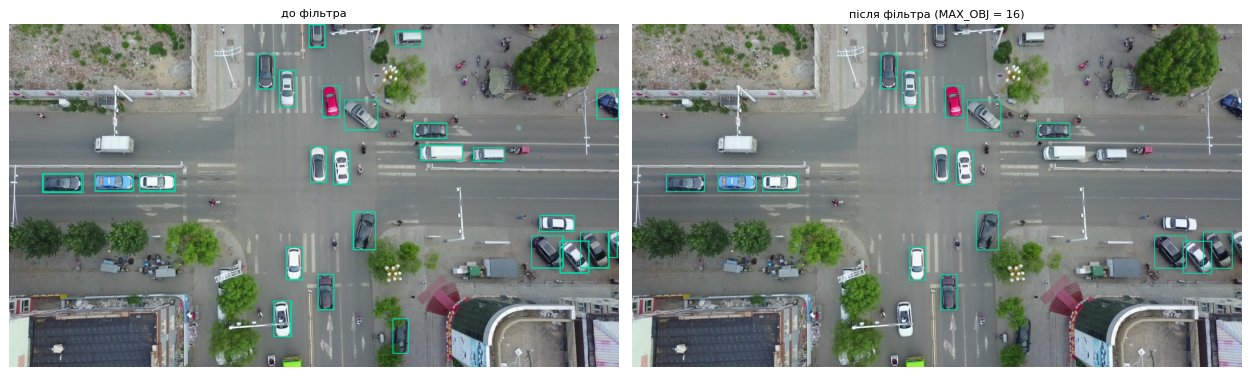

✅ 16 боксів, з них 16 — справжні машини


In [7]:
MIN_SIDE, MAX_AREA_FRAC, MIN_SCORE = 8, 0.05, 0.4
MAX_OBJ = 16   # TODO 2.1б: від 4 до 32


def filter_boxes(d):
    w, h = d.boxes[:, 2] - d.boxes[:, 0], d.boxes[:, 3] - d.boxes[:, 1]
    ok = (np.minimum(w, h) >= MIN_SIDE) & ((w * h) <= (MAX_AREA_FRAC * W * H)) & (d.scores >= MIN_SCORE)   # TODO 2.1а: умова на сторону, площу й score
    d = P.nms(d.take(np.flatnonzero(ok)), 0.6, class_aware=False)
    keep = []                                       # від більших до менших: вкладений бокс — частина об'єкта
    for i in np.argsort(-(d.boxes[:, 2] - d.boxes[:, 0]) * (d.boxes[:, 3] - d.boxes[:, 1])):
        if not keep or P.box_ios(d.boxes[i], d.boxes[keep]).max() < 0.8:
            keep.append(i)
    d = d.take(np.array(keep, int))
    return d.take(np.argsort(-d.scores)[:MAX_OBJ])


d_key = detect(key, PROMPT)
boxes = filter_boxes(d_key)
r0, r1 = P.match_pr(d_key.boxes, gt0), P.match_pr(boxes.boxes, gt0)
print(f'до фільтра:    {len(d_key):2d} боксів, TP {r0["tp"]}, FP {r0["fp"]}')
print(f'після фільтра: {len(boxes):2d} боксів, TP {r1["tp"]}, FP {r1["fp"]}')
w_, h_ = boxes.boxes[:, 2] - boxes.boxes[:, 0], boxes.boxes[:, 3] - boxes.boxes[:, 1]
P.show_row([P.draw_boxes(key, d_key.boxes, thick=2), P.draw_boxes(key, boxes.boxes, thick=2)],
           ['до фільтра', f'після фільтра (MAX_OBJ = {MAX_OBJ})'], size=7)
check(4 <= MAX_OBJ <= 32 and 0 < len(boxes) <= MAX_OBJ and (np.minimum(w_, h_) >= MIN_SIDE).all()
      and (w_ * h_ <= MAX_AREA_FRAC * W * H).all() and (boxes.scores >= MIN_SCORE).all() and r1['tp'] >= 0.8 * len(boxes),
      f'{len(boxes)} боксів, з них {r1["tp"]} — справжні машини',
      'фільтр пропустив бокс, що порушує умову, або MAX_OBJ поза 4–32 — перевірте умову ok')

## 2.2 · SAM 2.1: бокси → маски (≈ 10 хв)
Енкодер SAM — найдорожчий вузол, і його платять **раз на кадр** (`set_image`); далі декодер для кожного промпта — мілісекунди
(слайд «Три режими в коді: SAM 2.1 image API», режим «промпт із моделі»). Бокс — однозначний промпт, тож одна маска на бокс:
`multimask_output=False` (слайд «Як SAM вирішує неоднозначність»).

**TODO 2.2.** Запустіть енкодер на ключовому кадрі й отримайте маски для **всіх** боксів **одним** викликом.

*Підказки:* `pred.set_image(key)`; `pred.predict(box=boxes.boxes, multimask_output=False)` повертає
`(маски, predicted_iou, низькороздільні логіти)`.

масок 16, predicted_iou: медіана 0.96, мін 0.93; частка пікселів маски всередині свого боксу: 100%


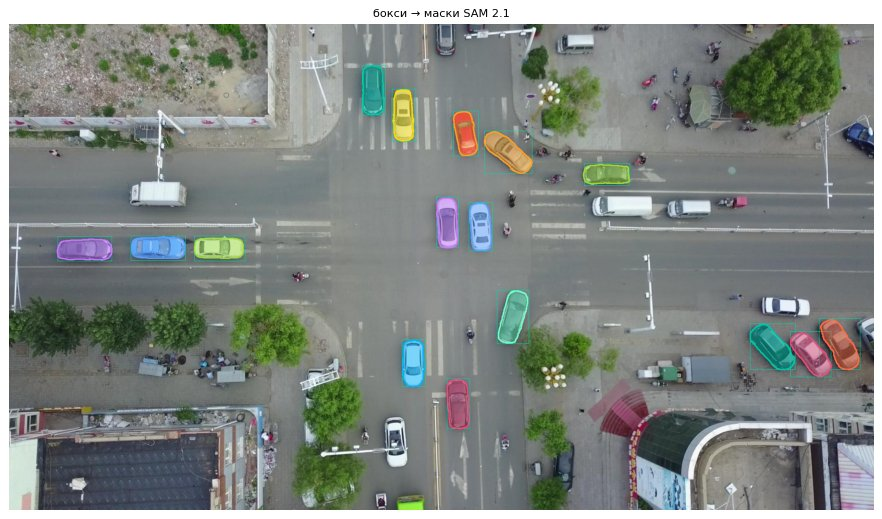

✅ маски побудовано


In [9]:
pred = P.load_sam2_image(SAM2, DEVICE)
with torch.inference_mode(), P.autocast(DEVICE):
    pred.set_image(key)   # TODO 2.2: енкодер — раз на кадр
    masks, iou, _ = pred.predict(box=boxes.boxes, multimask_output=False)  # TODO 2.2: усі бокси одним викликом, одна маска на бокс

masks = np.asarray(masks).reshape(len(boxes), H, W) > 0
iou = np.asarray(iou).ravel()
inside = np.mean([m[int(b[1]):int(np.ceil(b[3])), int(b[0]):int(np.ceil(b[2]))].sum() / max(m.sum(), 1)
                  for m, b in zip(masks, boxes.boxes)])
print(f'масок {len(masks)}, predicted_iou: медіана {np.median(iou):.2f}, мін {iou.min():.2f}; '
      f'частка пікселів маски всередині свого боксу: {inside:.0%}')
P.show_row([P.overlay_masks(P.draw_boxes(key, boxes.boxes, thick=1), list(masks))], ['бокси → маски SAM 2.1'], size=10)
check(len(masks) == len(boxes) and np.median(iou) >= 0.7 and inside >= 0.9,
      'маски побудовано', 'масок не стільки, скільки боксів, або вони не в боксах — перевірте predict(box=...)')

# Частина 3 · Поширення по відео

## 3.1 · SAM 2: маски по всьому кліпу (≈ 15 хв)
SAM 2 обробляє кадри потоком і тримає **банк пам'яті**: кілька останніх кадрів, кадри з промптами й «вказівники»
на об'єкти. Так зберігається ідентичність, а голова оклюзії прибирає маску, коли об'єкта не видно (слайд
«SAM 2: архітектура з пам'яттю»). Код повторює слайд «Композиція в 15 рядках»: `init_state` → промпти → `propagate_in_video`.

Функція `propagate` уже написана; усі промпти — і на кадрі 0, і корекції в кроці 3.2 — йдуть через `add_box`.

**TODO 3.1.** Допишіть `add_box`: бокс `box` для об'єкта `obj` на кадрі `k`.

*Підказка:* `vp.add_new_points_or_box(state, frame_idx=..., obj_id=..., box=...)`.

frame loading (JPEG): 100%|██████████| 60/60 [00:03<00:00, 18.04it/s]
/usr/local/lib/python3.13/dist-packages/sam2/sam2_video_predictor.py:786: UserWarning: inputs.is_cuda() INTERNAL ASSERT FAILED at "/tmp/pip-req-build-m19sttis/sam2/csrc/connected_components.cu":215, please report a bug to PyTorch. inputs must be a CUDA tensor
Exception raised from get_connected_componnets at /tmp/pip-req-build-m19sttis/sam2/csrc/connected_components.cu:215 (most recent call first):
frame #0: c10::Error::Error(c10::SourceLocation, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >) + 0x9d (0x7f1712d7305d in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #1: c10::detail::torchCheckFail(char const*, char const*, unsigned int, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > const&) + 0xc3 (0x7f1712d076fd in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #2: c10::detail::torchInternalAssertFail(char const*

,кадрів,"IoU, де видно","втрачено, де видно","маска, де об'єкт сховано / пішов","перескок на сусіда, кадрів"
obj 0 / трек 20,60,0.782,0,4/4,0
obj 1 / трек 13,60,0.851,0,5/46,0
obj 2 / трек 15,60,0.769,1,0/18,0
obj 3 / трек 32,60,0.786,5,0/9,0
obj 4 / трек 2,60,0.814,0,1/4,0
obj 5 / трек 17,60,0.738,0,3/33,0
obj 6 / трек 19,60,0.806,0,0/0,0
obj 7 / трек 5,60,0.585,12,3/19,0
obj 8 / трек 33,60,0.819,1,1/14,0
obj 9 / трек 18,60,0.8,0,3/19,0


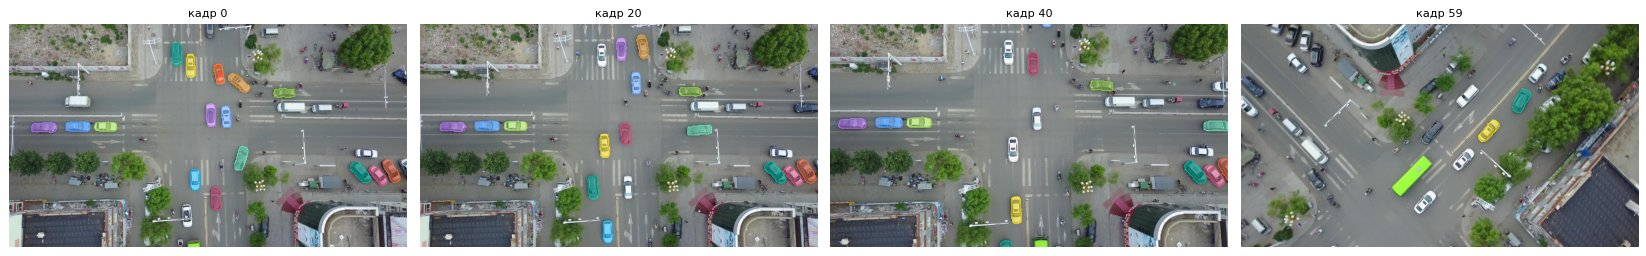

✅ 16 об'єктів ведуться, медіанний IoU 0.78


In [10]:
vp = P.load_sam2_video(SAM2, DEVICE)


def add_box(state, k, obj, box):
    vp.add_new_points_or_box(state, frame_idx=k, obj_id=obj, box=box)   # TODO 3.1: бокс об'єкта obj на кадрі k


def propagate(boxes0, corrections=None, on_frame=None):
    # boxes0 — бокси на кадрі 0; corrections = {кадр: {об'єкт: бокс}} — промпти в середині ролика.
    # on_frame(k, ids, маски) — для експорту в кроці 4.1. Повертає P.VideoRun: бокси й площі масок по кадрах, мс.
    n = len(boxes0)
    track = {o: np.full((T, 4), np.nan, np.float32) for o in range(n)}
    area = {o: np.zeros(T, np.float32) for o in range(n)}
    small, ms = {}, []
    with torch.inference_mode(), P.autocast(DEVICE):
        state = vp.init_state(video_path=str(clip.dir), offload_video_to_cpu=True)
        for o, b in enumerate(boxes0):
            add_box(state, 0, o, np.asarray(b, np.float32))
        for k, objs in (corrections or {}).items():
            for o, b in objs.items():
                add_box(state, int(k), int(o), np.asarray(b, np.float32))
        it = iter(vp.propagate_in_video(state))
        while True:
            with P.timed(ms):
                try:
                    k, ids, logits = next(it)
                except StopIteration:
                    break
                m = (logits[:, 0] > 0).cpu().numpy()             # (об'єктів, H, W)
            small[k] = {}
            for j, o in enumerate(int(i) for i in ids):
                area[o][k] = m[j].sum()
                small[k][o] = m[j][::4, ::4]
                b = P.mask_to_box(m[j])
                if b is not None:
                    track[o][k] = b
            if on_frame is not None:
                on_frame(k, [int(i) for i in ids], m)
        vp.reset_state(state)
    return P.VideoRun(track, area, small, ms[:-1], 0.0)


run = propagate(boxes.boxes)
# кожен об'єкт — з «своїм» GT-треком на кадрі 0; далі покадрово: IoU зі своїм, втрата, перескок на сусіда
M = P.box_iou(boxes.boxes, gt0)
tids0 = gt[gt.k == 0].tid.values
match = {o: int(tids0[M[o].argmax()]) for o in range(len(boxes)) if M[o].max() >= 0.5}
ev = {o: P.track_eval(run.boxes[o], gt, t) for o, t in match.items()}
summary = P.summarize_tracks({f'obj {o} / трек {t}': ev[o] for o, t in match.items()})
display(summary)
ks = [0, T // 3, 2 * T // 3, T - 1]
P.show_row([P.overlay_masks(clip.read(k), [run.small[k][o] for o in run.objs], ids=run.objs) for k in ks],
           [f'кадр {k}' for k in ks], size=4.6, ncols=4)
iou_vis = pd.to_numeric(summary['IoU, де видно']).median()
check(len(match) >= 0.5 * len(boxes) and iou_vis >= 0.6, f'{len(match)} об\'єктів ведуться, медіанний IoU {iou_vis:.2f}',
      'маски не поширились — перевірте add_box: frame_idx, obj_id і box')

✍️ **Зверніть увагу** на стовпці зведення: де SAM 2 втратив видиму машину, де лишив маску на машині, яку вже сховано
(«домальовує»), де маска перескочила на сусіда. Знадобиться для питань 5.1–5.2.

## 3.2 · Корекція одним боксом у середині ролика (≈ 10 хв)
Маска поїхала — оператор дає **один** бокс на проблемному кадрі, і SAM 2 перераховує все від цієї точки
(слайд «Promptable Visual Segmentation»). Клітинка нижче знаходить об'єкт, у якого найбільше кадрів, де маска не на «своїй»
машині, поки ту видно, і перший такий кадр. Бокс «оператора» беремо з розмітки VisDrone.

**TODO 3.2.** Складіть `corrections` — словник `{кадр: {об'єкт: бокс}}` з одним боксом `g_box` для об'єкта `o_fix`
на кадрі `k_fix`.

obj 7: 12 проблемних кадрів, перший — 48


frame loading (JPEG): 100%|██████████| 60/60 [00:03<00:00, 18.50it/s]
/usr/local/lib/python3.13/dist-packages/sam2/sam2_video_predictor.py:786: UserWarning: inputs.is_cuda() INTERNAL ASSERT FAILED at "/tmp/pip-req-build-m19sttis/sam2/csrc/connected_components.cu":215, please report a bug to PyTorch. inputs must be a CUDA tensor
Exception raised from get_connected_componnets at /tmp/pip-req-build-m19sttis/sam2/csrc/connected_components.cu:215 (most recent call first):
frame #0: c10::Error::Error(c10::SourceLocation, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >) + 0x9d (0x7f1712d7305d in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #1: c10::detail::torchCheckFail(char const*, char const*, unsigned int, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > const&) + 0xc3 (0x7f1712d076fd in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #2: c10::detail::torchInternalAssertFail(char const*

,,кадрів,"IoU, де видно","втрачено, де видно","маска, де об'єкт сховано / пішов","перескок на сусіда, кадрів"
до корекції,obj 7,60,0.585,12,3/19,0
бокс на кадрі 48,obj 7,60,0.837,0,3/19,0


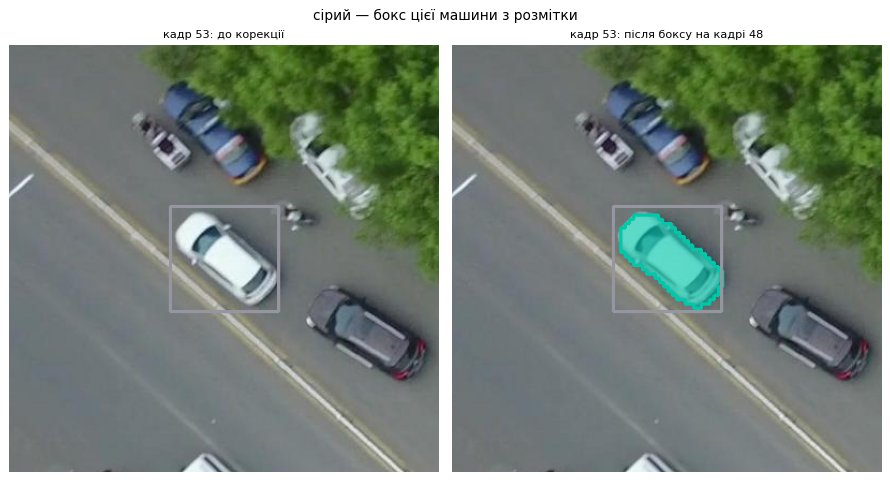

✅ проблемних кадрів: 12 → 0


In [11]:
bad_vis = {o: int(((e.state == 'видно') & ((e.iou < 0.3) | e.switch)).sum()) for o, e in ev.items()}
o_fix = max(bad_vis, key=bad_vis.get)
if bad_vis[o_fix] == 0:
    print('SAM 2 на цьому кліпі не помилився на жодній видимій машині — корекція не потрібна.')
else:
    e = ev[o_fix]
    k_fix = int(np.flatnonzero((e.state.values == 'видно') & ((e.iou.values < 0.3) | e.switch.values))[0])
    g_box = gt[(gt.k == k_fix) & (gt.tid == match[o_fix])][['x0', 'y0', 'x1', 'y1']].values[0]
    print(f'obj {o_fix}: {bad_vis[o_fix]} проблемних кадрів, перший — {k_fix}')

    corrections = {k_fix: {o_fix: g_box}}   # TODO 3.2: {кадр: {об'єкт: бокс}}
    run_fix = propagate(boxes.boxes, corrections)
    ev_fix = P.track_eval(run_fix.boxes[o_fix], gt, match[o_fix])
    display(pd.concat({'до корекції': P.summarize_tracks({f'obj {o_fix}': e}),
                       f'бокс на кадрі {k_fix}': P.summarize_tracks({f'obj {o_fix}': ev_fix})}))
    k_show = min(T - 1, k_fix + 5)
    fr = clip.read(k_show)
    gb = gt[(gt.k == k_show) & (gt.tid == match[o_fix])][['x0', 'y0', 'x1', 'y1']].values
    centre = gb[0] if len(gb) else g_box
    pics = [P.crop_around(P.draw_boxes(P.overlay_masks(fr, [r.small[k_show].get(o_fix, np.zeros((1, 1), bool))], alpha=.6),
                                       gb, color=(150, 150, 160), thick=2), centre, pad=150)[0] for r in (run, run_fix)]
    P.show_row(pics, [f'кадр {k_show}: до корекції', f'кадр {k_show}: після боксу на кадрі {k_fix}'], size=5,
               suptitle='сірий — бокс цієї машини з розмітки')
    bad = lambda d: int(((d.state == 'видно') & ((d.iou < 0.3) | d.switch)).sum())
    check(corrections == {k_fix: {o_fix: g_box}} and bad(ev_fix) < bad(e),
          f'проблемних кадрів: {bad(e)} → {bad(ev_fix)}', 'корекція не спрацювала — перевірте формат corrections')

# Частина 4 · Експорт і вартість

## 4.1 · Експорт (≈ 10 хв)
Для кожного кадру записуємо: `masks/` — PNG, де значення пікселя = ID об'єкта + 1 (0 — фон); `cutout/` — об'єкти на
приглушеному фоні; `overlay.mp4` — відео з масками; `annotations.json` — COCO з RLE-масками й `track_id`.
Експорт іде з корекцією з кроку 3.2.

**TODO 4.1.** Допишіть вирізання: там, де є будь-який об'єкт (`ids > 0`), — кадр як є, решта — кадр, приглушений до 15 %.

*Підказка:* `np.where(умова[..., None], що_всередині, що_зовні)`; приглушений кадр — `(fr * 0.15).astype(np.uint8)`.

frame loading (JPEG): 100%|██████████| 60/60 [00:03<00:00, 17.46it/s]
/usr/local/lib/python3.13/dist-packages/sam2/sam2_video_predictor.py:786: UserWarning: inputs.is_cuda() INTERNAL ASSERT FAILED at "/tmp/pip-req-build-m19sttis/sam2/csrc/connected_components.cu":215, please report a bug to PyTorch. inputs must be a CUDA tensor
Exception raised from get_connected_componnets at /tmp/pip-req-build-m19sttis/sam2/csrc/connected_components.cu:215 (most recent call first):
frame #0: c10::Error::Error(c10::SourceLocation, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >) + 0x9d (0x7f1712d7305d in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #1: c10::detail::torchCheckFail(char const*, char const*, unsigned int, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > const&) + 0xc3 (0x7f1712d076fd in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #2: c10::detail::torchInternalAssertFail(char const*

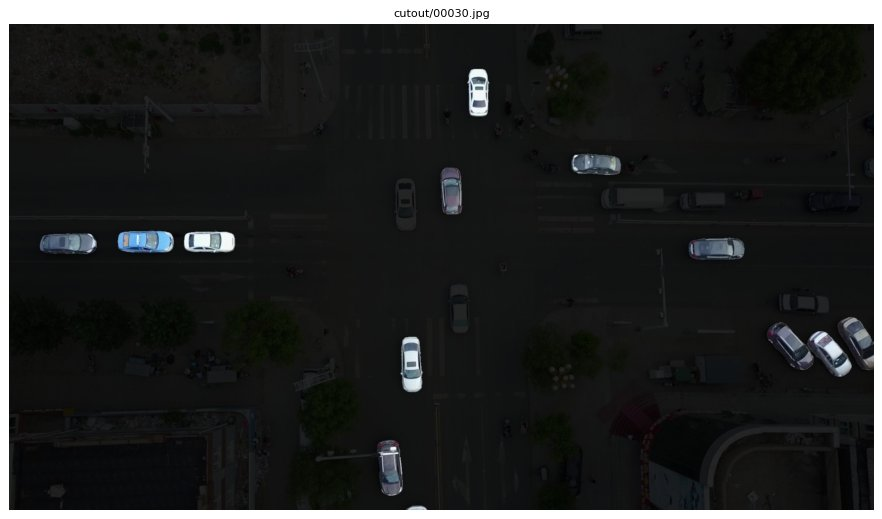

✅ експорт: 60 масок, 60 вирізань, 730 анотацій → outputs/export


In [12]:
from pycocotools import mask as mask_utils

EXPORT = OUT_DIR / 'export'
for sub in ('masks', 'cutout'):
    (EXPORT / sub).mkdir(parents=True, exist_ok=True)
writer = cv2.VideoWriter(str(EXPORT / 'overlay.mp4'), cv2.VideoWriter_fourcc(*'mp4v'), 15, (W, H))
coco = {'images': [], 'annotations': [], 'categories': [{'id': 1, 'name': 'vehicle'}]}


def on_frame(k, obj_ids, frame_masks):
    fr = clip.read(k)
    ids = np.zeros((H, W), np.uint16)
    for o, m in zip(obj_ids, frame_masks):
        ids[m] = o + 1
        if m.any():
            rle = mask_utils.encode(np.asfortranarray(m.astype(np.uint8)))
            rle['counts'] = rle['counts'].decode()
            coco['annotations'].append({'id': len(coco['annotations']) + 1, 'image_id': k, 'track_id': o, 'category_id': 1,
                                        'segmentation': rle, 'bbox': mask_utils.toBbox(rle).tolist(), 'area': float(m.sum())})
    coco['images'].append({'id': k, 'file_name': clip.frames[k].name, 'width': W, 'height': H})
    cut = np.where(ids[..., None] > 0, fr, (fr * 0.15).astype(np.uint8))   # TODO 4.1: об'єкти як є, фон — 15 % яскравості
    cv2.imwrite(str(EXPORT / 'masks' / f'{k:05d}.png'), ids)
    cv2.imwrite(str(EXPORT / 'cutout' / f'{k:05d}.jpg'), np.ascontiguousarray(cut[..., ::-1]))
    writer.write(np.ascontiguousarray(P.overlay_masks(fr, list(frame_masks), ids=list(obj_ids))[..., ::-1]))


final = propagate(boxes.boxes, corrections if bad_vis[o_fix] else None, on_frame=on_frame)
writer.release()
(EXPORT / 'annotations.json').write_text(json.dumps(coco))
n_png, n_cut = len(list((EXPORT / 'masks').glob('*.png'))), len(list((EXPORT / 'cutout').glob('*.jpg')))
k_mid = T // 2
P.show_row([cv2.imread(str(EXPORT / 'cutout' / f'{k_mid:05d}.jpg'))[..., ::-1]], [f'cutout/{k_mid:05d}.jpg'], size=10)
check(n_png == T and n_cut == T and len(coco['annotations']) > 0 and (EXPORT / 'overlay.mp4').stat().st_size > 0,
      f'експорт: {n_png} масок, {n_cut} вирізань, {len(coco["annotations"])} анотацій → {EXPORT}',
      'експорт неповний — перевірте рядок cut у on_frame')

## 4.2 · Скільки це коштує (≈ 10 хв, код готовий)
Вартість кадру композиції (слайд «Композиція в 15 рядках і її latency-бюджет»):

$$T_{frame} \approx \frac{T_{GDINO} + T_{SAM\,enc}}{K} + T_{SAM2\,enc} + n_{obj}\,(T_{mem} + T_{dec})$$

Детектор і енкодер SAM 2.1 працюють лише на ключових кадрах (раз на K кадрів), а SAM 2 — на кожному, і кожен об'єкт додає
свою пам'ять і декодер. Міряємо доданки й залежність від кількості об'єктів (для n більше за знайдене — зсунуті копії
боксів, лише щоб виміряти ціну). Просто запустіть клітинку.

In [13]:
t_gd = P.bench(lambda: detect(key, PROMPT), n_warmup=1, n_iter=5)['median_ms']


def sam_enc():
    with torch.inference_mode(), P.autocast(DEVICE):
        pred.set_image(key)


t_enc = P.bench(sam_enc, n_warmup=1, n_iter=5)['median_ms']
rng = np.random.default_rng(0)
cost = []
for n in N_OBJ_COST:
    reps = np.concatenate([boxes.boxes] * int(np.ceil(n / len(boxes))))[:n] + rng.normal(0, 2, (n, 4)).astype(np.float32)
    cost.append({'n_obj': n, 'SAM 2, мс/кадр': float(np.median(propagate(reps).ms))})
cost = pd.DataFrame(cost)
slope, icpt = np.polyfit(cost.n_obj, cost['SAM 2, мс/кадр'], 1)
nodes = pd.DataFrame([{'вузол': 'Grounding DINO, ключовий кадр', 'мс': t_gd},
                      {'вузол': 'SAM 2.1 енкодер (set_image)', 'мс': t_enc},
                      {'вузол': 'SAM 2 propagate: частина, що не залежить від n_obj', 'мс': icpt},
                      {'вузол': 'SAM 2 propagate: на кожен об\'єкт', 'мс': slope}])
nodes['FPS'] = 1000 / nodes['мс']
display(nodes.round(1))
display(cost.round(1))
K = 30
T_frame = (t_gd + t_enc) / K + icpt + len(boxes) * slope
print(f'залізо: {GPU}')
print(f'T_frame(K={K}, n_obj={len(boxes)}) ≈ ({t_gd:.0f} + {t_enc:.0f}) / {K} + {icpt:.0f} + {len(boxes)}·{slope:.1f} '
      f'= {T_frame:.0f} мс → {1000 / T_frame:.1f} FPS')

frame loading (JPEG): 100%|██████████| 60/60 [00:03<00:00, 16.89it/s]
/usr/local/lib/python3.13/dist-packages/sam2/sam2_video_predictor.py:786: UserWarning: inputs.is_cuda() INTERNAL ASSERT FAILED at "/tmp/pip-req-build-m19sttis/sam2/csrc/connected_components.cu":215, please report a bug to PyTorch. inputs must be a CUDA tensor
Exception raised from get_connected_componnets at /tmp/pip-req-build-m19sttis/sam2/csrc/connected_components.cu:215 (most recent call first):
frame #0: c10::Error::Error(c10::SourceLocation, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >) + 0x9d (0x7f1712d7305d in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #1: c10::detail::torchCheckFail(char const*, char const*, unsigned int, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > const&) + 0xc3 (0x7f1712d076fd in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #2: c10::detail::torchInternalAssertFail(char const*

,вузол,мс,FPS
0,"Grounding DINO, ключовий кадр",769.5,1.3
1,SAM 2.1 енкодер (set_image),272.3,3.7
2,"SAM 2 propagate: частина, що не залежить від n...",213.8,4.7
3,SAM 2 propagate: на кожен об'єкт,282.9,3.5


,n_obj,"SAM 2, мс/кадр"
0,1,544.0
1,2,742.1
2,4,1335.4
3,8,2469.1
4,16,4748.5


залізо: Tesla T4
T_frame(K=30, n_obj=16) ≈ (769 + 272) / 30 + 214 + 16·282.9 = 4775 мс → 0.2 FPS


# 5 · Питання (≈ 10 хв)
Відповідайте своїми словами, коротко. Формули не потрібні, числа беріть із виводів вище — переписувати таблиці не треба.

**5.1–5.2. Два провали.** Знайдіть у своїх результатах **два різні** провали пайплайна. Де шукати: таблиця 1.3
(формулювання, кома), пропущені машини на ключовому кадрі (1.2), що відсік фільтр (2.1), зведення 3.1 (втрата, «домальовування»
схованої машини, перескок на сусіда). Для кожного — по одному реченню:
- **що** видно: крок, номер кадру чи об'єкта, число з виводу;
- **чому** — ваша гіпотеза;
- **що робити** — прийом зі слайда «Каталог провалів: що робити» (без донавчання моделі).

✍️ *5.1:*

✍️ *5.2:*

**5.3.** Замовник хоче поставити цей пайплайн на борт дрона: «30 FPS, будь-який текстовий запит у польоті». Що відповісте
(2–3 речення)? Спирайтеся на свої цифри з 4.2 (слайди «Latency-бюджет: де зникає час», «SAM 2 чи класичний трекер?»,
«Правильне місце zero-shot у продакшені»).

✍️ *Ваша відповідь:*

## Бонус (за бажанням, не оцінюється)
- **Тайли.** На ключовому кадрі замість `detect(key, PROMPT)` спробуйте `P.detect_tiled(lambda im: detect(im, PROMPT), key)[0]`
  (тайли 640 з перекриттям 20 % + повний кадр, слайд «Дрібні об'єкти на великому кадрі»). Скільки машин додалось і скільки
  зайвих боксів прийшло разом із ними?
- **Більший SAM.** `SAM2 = 'sam2.1-large'` (спершу `python tools/fetch_sam_models.py --models sam2.1-large`): що змінилось
  у зведенні 3.1 і в мс/кадр?
- **Тепловізор.** Той самий пайплайн на ролику [HIT-UAV](https://github.com/suojiashun/HIT-UAV-Infrared-Thermal-Dataset):
  що деградувало сильніше — текстовий промпт (детектор) чи геометрія (маски SAM за боксом)? Відповідь знадобиться на занятті 12.

# Здача
Усе здається **одним архівом** через особистий кабінет LMS. Порядок:
1. **Kernel → Restart Kernel and Run All Cells**: ноутбук має виконатись від початку до кінця, з усіма ✅.
2. Заповніть таблиці й відповіді в клітинках «✍️».
3. Збережіть ноутбук (**Ctrl+S**) і запустіть клітинку нижче: вона збере в архів `dz6_<прізвище>.zip` ноутбук,
   `outputs/export/overlay.mp4` і `outputs/export/annotations.json`.
4. Прикріпіть **цей один архів** у особистому кабінеті LMS. Окремі файли, посилання на диск чи репозиторій не приймаються.

In [14]:
import zipfile

SURNAME = 'halunko'   # ✍️ прізвище латиницею, наприклад 'shevchenko'
NOTEBOOK = Path('02_grounded_sam2_video_student.ipynb')
FILES = [NOTEBOOK, OUT_DIR / 'export' / 'overlay.mp4', OUT_DIR / 'export' / 'annotations.json']

assert SURNAME, 'впишіть прізвище в SURNAME'
missing = [str(f) for f in FILES if not f.exists()]
assert not missing, f'немає файлів {missing}: виконайте всі клітинки й збережіть ноутбук'
archive = Path(f'dz6_{SURNAME}.zip')
with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in FILES:
        z.write(f, f.as_posix())
    names = z.namelist()
print(f'→ {archive.resolve()} ({archive.stat().st_size / 2**20:.1f} МБ): {", ".join(names)}')
print('Прикріпіть цей архів в особистому кабінеті LMS.')

AssertionError: немає файлів ['02_grounded_sam2_video_student.ipynb']: виконайте всі клітинки й збережіть ноутбук